# Cohen et al. 2021 — Multiple Myeloma · 03 Signatures
`score_genes` module signatures (Gast / pSom / Crest) with the union control pool, shown as
**raw** per-cell scores on the manifold (deliverable panels). Gate 2 is judged on the module
geography: a single Gast/pSom-origin → terminal-Crest gradient (non-branching).

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_cb, exist_ok=True)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print('%s: %d/%d genes present' % (l, g.size, feat[src].size))
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

Gast: 69/81 genes present
pSom: 80/98 genes present
Crest: 101/104 genes present
raw module means: {'Gast': -0.0218, 'pSom': 0.0143, 'Crest': 0.0013}


In [ ]:
# GATE 2 — module geography. Non-branching test: single pSom/Gast-origin -> terminal-Crest gradient,
# Crest an INVERSE terminal readout (not a co-expression hub), Gast/pSom not cross-repressing.
print('smoothed geography correlations:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print('  %s vs %s: r = %+.2f' % (a,b,np.corrcoef(adata.obs[a],adata.obs[b])[0,1]))
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho, smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    print('  %s: rho = %+.3f' % (s, spearmanr(t, adata.obs[s])[0]))
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print('Neural-crest-high decile mean pseudotime = %.2f (terminal if ~1)' % tn[hi.values].mean())
pz = (adata.obs['pSom']-adata.obs['pSom'].mean())/adata.obs['pSom'].std()
cz = (adata.obs['Crest']-adata.obs['Crest'].mean())/adata.obs['Crest'].std()
joint = ((pz>0.5)&(cz>0.5)).mean(); exp = (pz>0.5).mean()*(cz>0.5).mean()
print('joint pSom&Crest-high enrichment = %.2f (<1 = inverse gradient, not a hub)' % (joint/exp))
print('GATE 2 = GO (non-branching): single Gast/pSom-origin -> terminal-Crest axis; Crest inversely enriched.')
print('GATE 3 = NA: no bifurcation (Gast/pSom near-orthogonal r=+0.07, no competing arms).')

smoothed geography correlations:
  Gast_sm vs pSom_sm: r = +0.07
  Crest_sm vs Gast_sm: r = -0.69
  Crest_sm vs pSom_sm: r = -0.61
gradient along pseudotime (Spearman rho, smoothed):
  Gast_sm: rho = -0.542
  pSom_sm: rho = -0.135
  Crest_sm: rho = +0.565
Neural-crest-high decile mean pseudotime = 0.67 (terminal if ~1)
joint pSom&Crest-high enrichment = 0.22 (<1 = inverse gradient, not a hub)
GATE 2 = GO (non-branching): single Gast/pSom-origin -> terminal-Crest axis; Crest inversely enriched.
GATE 3 = NA: no bifurcation (Gast/pSom near-orthogonal r=+0.07, no competing arms).


saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


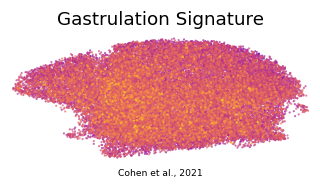

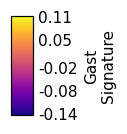

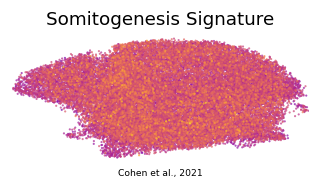

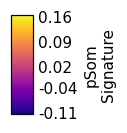

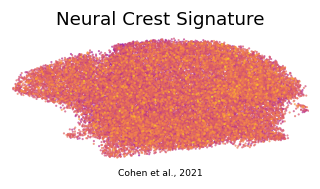

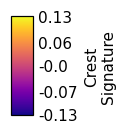

In [ ]:
# signature deliverable panels — RAW per-cell scores, house (3.5,1.5) layout, shared orientation.
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=8, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Cohen et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [ ]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (33019, 31585)
